# A neural network that reads raw light curves

### ZTF Summer School: building a sequence classifier from scratch

No prior neural-network experience is assumed. In about an hour we build, train and honestly
evaluate a deep classifier that reads ZTF light curves **as they are** (irregular, multi-band, a
different length for every object) with no hand-crafted features anywhere. It sorts them into the
six classes of the BTS benchmark that ships with this repository: SN Ia, core-collapse supernovae
(SN_CC), superluminous supernovae (SLSN), AGN, tidal disruption events (TDE) and cataclysmic
variables (CV).

The model is small enough to train on a laptop CPU in a few minutes, and every line of it is in
this notebook.

In [1]:
import sys, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import torch
import torch.nn as nn

sys.path.insert(0, "../..")          # the repository root, so that `flare` is this checkout
from flare import benchmark as B
from flare import data as D

SIX = B.SIX                          # SN_Ia, SN_CC, SLSN, AGN, TDE, CV
# one fixed colour per class: magma at six evenly spaced points, stopping before the near-white end
CLASS_COLOR = dict(zip(SIX, [to_hex(c) for c in plt.cm.magma(np.linspace(0.05, 0.85, 6))]))
BAND_COLOR = {"g": to_hex(plt.cm.magma(0.30)), "r": to_hex(plt.cm.magma(0.68))}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
torch.set_num_threads(8)             # a laptop-sized CPU budget
torch.manual_seed(0); np.random.seed(0)
print("Setup OK, torch", torch.__version__)

Setup OK, torch 2.10.0+cu128


## 1. The data, and the three properties that will shape the model

We look at the *shape* of the data, not the astronomy, for a moment. Each split of the benchmark
is a table with one row per object; the light curve of each object is an `.npz` file of events
(one row per detection) under `benchmark/events/`.

train:  7347 objects | SN_Ia 5011, SN_CC 1791, SLSN 109, AGN 176, TDE 47, CV 213


val  :  1575 objects | SN_Ia 1074, SN_CC 384, SLSN 23, AGN 37, TDE 11, CV 46
test :  1575 objects | SN_Ia 1074, SN_CC 384, SLSN 24, AGN 38, TDE 10, CV 45


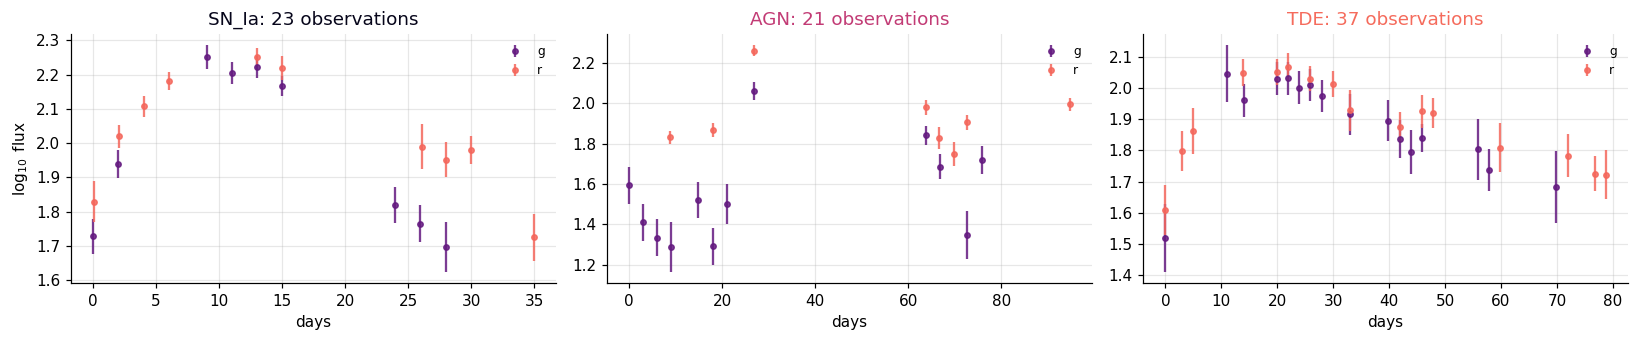

observations per object (first 100 days): min=8, median=25, max=361


In [2]:
B.prepare()                          # unpacks benchmark/light_curves.tar.gz on first use
tables = {s: pd.read_csv(B.BENCHMARK / "splits" / f"{s}.csv") for s in ["train", "val", "test"]}
for s, t in tables.items():
    t["path"] = [str(B.BENCHMARK / p) for p in t.filepath]
    t["y"] = [SIX.index(c) for c in t.cls]
    print(f"{s:5s}: {len(t):5d} objects |",
          ", ".join(f"{c} {n}" for c, n in t.cls.value_counts().reindex(SIX).items()))

train = tables["train"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, cls in zip(axes, ["SN_Ia", "AGN", "TDE"]):
    sub_c = train[train.cls == cls].sort_values("n_events")
    row = sub_c.iloc[len(sub_c) // 2]               # the median object of the class
    arr = D.load_events(row.path)
    bands = D.reconstruct_bands(arr)
    for name in ["g", "r"]:
        if name in bands:
            ax.errorbar(bands[name].t, bands[name].logflux, yerr=bands[name].logflux_err,
                        fmt="o", ms=3.5, color=BAND_COLOR[name], alpha=0.85, label=name)
    ax.set_title(f"{cls}: {len(arr)} observations", color=CLASS_COLOR[cls])
    ax.set_xlabel("days"); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel(r"$\log_{10}$ flux")
plt.tight_layout(); plt.show()
n_obs = train.n_events.to_numpy()         # detections inside the first 100 days
print(f"observations per object (first 100 days): min={n_obs.min()}, "
      f"median={int(np.median(n_obs))}, max={n_obs.max()}")

Three properties, three design problems:

| # | Property | Problem for a model | Our answer |
|---|---|---|---|
| **P1** | Different number of observations per object, at irregular times | the input is not a fixed-size vector; "observation 7" is a different time for every object | read in order with a memory, and give the model the **clock** (the time step is an input) |
| **P2** | g / r / i filters interleave in one stream | the same flux means different things in different bands | the band **re-tunes** the network (FiLM) |
| **P3** | one label per object, whatever its length | many per-night vectors must become one | the model **learns where to look** (attention pooling) |

A network with a fixed number of inputs fails at P1 immediately: padding to the longest object
misaligns time, and resampling onto a grid invents data inside week-long gaps. The way out is a
**recurrent** network, which reads one observation at a time while carrying a memory vector. Two
learned gates decide, at each step, how much of the old memory to keep and how much of the new
observation to write. That cell is the **GRU**.

## 2. The whole architecture, in about 30 lines

We read it against P1 to P3: every block answers one of them.

In [3]:
class LightCurveGRU(nn.Module):
    '''FiLM-conditioned GRU with attention pooling, for raw event streams.'''

    def __init__(self, d=48, n_layers=2, n_classes=6, use_film=True):
        super().__init__()
        self.use_film = use_film
        self.embed = nn.Linear(4, d)        # dt_start, dt_prev, flux, err  (P1)
        self.film  = nn.Linear(3, 2 * d)    # band one-hot -> per-unit scale+shift (P2)
        self.gru   = nn.GRU(d, d, num_layers=n_layers, batch_first=True)
        self.score = nn.Linear(d, 1)        # attention: one score per night (P3)
        self.head  = nn.Linear(d, n_classes)

    def forward(self, x, band, pad):
        h = self.embed(x)                            # (batch, nights, d)
        if self.use_film:
            gamma, beta = self.film(band).chunk(2, -1)
            h = h * (1 + gamma) + beta               # the band re-tunes h  (P2)
        h, _ = self.gru(h)                           # memory through time  (P1)
        a = self.score(h).squeeze(-1)
        a = a.masked_fill(pad, -1e9).softmax(-1)     # padded nights: weight 0
        z = (h * a.unsqueeze(-1)).sum(1)             # learned summary      (P3)
        return self.head(z), a

print(f"{sum(p.numel() for p in LightCurveGRU().parameters()):,} parameters")

29,191 parameters


## 3. From npz files to padded tensors

Objects have different lengths, so a batch pads the short ones with zeros and carries a `pad`
mask that tells the attention to ignore those slots. We standardise the flux with **train-only**
statistics: the rule that the test set never informs training applies to normalisation too.

To keep CPU training quick we cap each light curve at its first 120 observations and train on a
class-balanced subset of the train split: at most 700 objects per class, keeping every example
of the rare classes.

In [4]:
CAP = 120     # cap the sequence length to keep CPU training quick

def build_tensors(df, stats=None):
    xs, bands, lens = [], [], []
    for path in df.path:
        arr = D.load_events(path)[:CAP]
        x = np.stack([np.log1p(arr[:, D.COL["dt"]]),
                      np.log1p(arr[:, D.COL["dt_prev"]]),
                      arr[:, D.COL["logflux"]],
                      arr[:, D.COL["logflux_err"]]], 1).astype(np.float32)
        b = np.eye(3, dtype=np.float32)[np.clip(arr[:, D.COL["band_id"]].astype(int), 0, 2)]
        xs.append(x); bands.append(b); lens.append(len(arr))
    L = max(lens)
    X  = np.zeros((len(xs), L, 4), np.float32)
    Bd = np.zeros((len(xs), L, 3), np.float32)
    P  = np.ones((len(xs), L), bool)
    for i, (x, b, n) in enumerate(zip(xs, bands, lens)):
        X[i, :n], Bd[i, :n], P[i, :n] = x, b, False
    if stats is None:
        stats = (X[..., 2][~P].mean(), X[..., 2][~P].std(),
                 X[..., 3][~P].mean(), X[..., 3][~P].std())
    fm, fs, em, es = stats
    X[..., 2] = np.where(P, 0, (X[..., 2] - fm) / fs)
    X[..., 3] = np.where(P, 0, (X[..., 3] - em) / es)
    T = torch.tensor
    return (T(X), T(Bd), T(P), T(df.y.to_numpy())), stats

sub = (train.groupby("cls", group_keys=False)
       .apply(lambda g: g.sample(min(len(g), 700), random_state=0)))
print(f"training subset: {len(sub)} objects |",
      ", ".join(f"{c} {n}" for c, n in sub.cls.value_counts().reindex(SIX).items()))

t0 = time.time()
train_T, stats = build_tensors(sub)
val_T,  _ = build_tensors(tables["val"], stats)
test_T, _ = build_tensors(tables["test"], stats)
print(f"tensors built in {time.time()-t0:.0f}s, train {tuple(train_T[0].shape)}")

training subset: 1945 objects | SN_Ia 700, SN_CC 700, SLSN 109, AGN 176, TDE 47, CV 213


tensors built in 46s, train (1945, 120, 4)


## 4. Training

Training is one idea repeated: predict, measure the error (the *loss*), nudge every weight
slightly against its share of the blame, and repeat. `Adam` is gradient descent with a step size
per weight. The class weights stop the 700 SN Ia of the subset from drowning the 47 TDEs, and we
keep the weights of the epoch with the best balanced accuracy on the validation split (early
stopping), so the test split plays no part in any choice.

In [5]:
from sklearn.metrics import balanced_accuracy_score

def train_model(model, train_T, val_T, epochs=30, bs=128, lr=3e-3):
    X, Bd, P, y = train_T
    counts = torch.bincount(y, minlength=6).float()
    wclass = (len(y) / (6 * counts)).clamp(max=30)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.CrossEntropyLoss(weight=wclass)
    best, best_state = -1.0, None
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(y))
        tot = 0.0
        for i in range(0, len(y), bs):
            ix = perm[i:i + bs]
            logits, _ = model(X[ix], Bd[ix], P[ix])
            loss = lossf(logits, y[ix])
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(ix)
        model.eval()
        with torch.no_grad():
            lv, _ = model(*val_T[:3])
        bal = balanced_accuracy_score(val_T[3].numpy(), lv.argmax(1).numpy())
        if bal > best:
            best, best_ep = bal, ep
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if ep == 1 or ep % 3 == 0:
            print(f"  epoch {ep:2d}: train loss {tot/len(y):.3f}   val balanced acc {bal:.3f}")
    model.load_state_dict(best_state)                # state_dict keeps every buffer
    print(f"kept epoch {best_ep} (val balanced acc {best:.3f}); {time.time()-t0:.0f}s")
    return model

torch.manual_seed(0)
net = LightCurveGRU(use_film=True)
net = train_model(net, train_T, val_T)

  epoch  1: train loss 1.716   val balanced acc 0.366


  epoch  3: train loss 1.328   val balanced acc 0.473


  epoch  6: train loss 1.027   val balanced acc 0.559


  epoch  9: train loss 0.885   val balanced acc 0.589


  epoch 12: train loss 0.766   val balanced acc 0.639


...

  epoch 18: train loss 0.650   val balanced acc 0.563


  epoch 21: train loss 0.523   val balanced acc 0.645


  epoch 24: train loss 0.448   val balanced acc 0.662


  epoch 27: train loss 0.459   val balanced acc 0.651


  epoch 30: train loss 0.314   val balanced acc 0.654
kept epoch 29 (val balanced acc 0.699); 67s


## 5. Does the band conditioning actually matter?

We never take an architectural choice on faith: we switch it off and measure.

In [6]:
torch.manual_seed(0)
blind = LightCurveGRU(use_film=False)
print("band-blind GRU (FiLM off):")
blind = train_model(blind, train_T, val_T)

band-blind GRU (FiLM off):


  epoch  1: train loss 1.721   val balanced acc 0.335


  epoch  3: train loss 1.359   val balanced acc 0.454


  epoch  6: train loss 1.132   val balanced acc 0.502


  epoch  9: train loss 1.077   val balanced acc 0.517


...

  epoch 18: train loss 0.901   val balanced acc 0.534


  epoch 21: train loss 0.857   val balanced acc 0.541


  epoch 24: train loss 0.798   val balanced acc 0.559


  epoch 27: train loss 0.743   val balanced acc 0.544


  epoch 30: train loss 0.636   val balanced acc 0.570
kept epoch 30 (val balanced acc 0.570); 58s


## 6. The full evaluation report

Accuracy alone says little when the classes are this imbalanced (two thirds of the test split are
SN Ia). We report the full picture: balanced accuracy, macro F1, per-class precision and recall,
ranking quality (macro AUPRC), the confusion matrix, and whether the probabilities are *honest*
(a reliability diagram and the expected calibration error).

In [7]:
from sklearn.metrics import classification_report, f1_score, average_precision_score

def full_report(model, T, name):
    model.eval()
    with torch.no_grad():
        logits, attn = model(*T[:3])
        proba = logits.softmax(-1).numpy()
    y = T[3].numpy(); pred = proba.argmax(1)
    auprc = np.mean([average_precision_score((y == c).astype(int), proba[:, c])
                     for c in range(6)])
    print(f"===== {name} =====")
    print(f"accuracy {(pred == y).mean():.4f} | balanced "
          f"{balanced_accuracy_score(y, pred):.4f} | macro F1 "
          f"{f1_score(y, pred, average='macro'):.4f} | macro AUPRC {auprc:.4f}\n")
    print(classification_report(y, pred, labels=range(6), target_names=SIX, digits=3,
                                zero_division=0))
    return proba, attn

proba_blind, _ = full_report(blind, test_T, "band-blind GRU")
proba_net, attn = full_report(net, test_T, "FiLM-GRU")

===== band-blind GRU =====
accuracy 0.6463 | balanced 0.6000 | macro F1 0.3883 | macro AUPRC 0.5072

              precision    recall  f1-score   support

       SN_Ia      0.920     0.714     0.804      1074
       SN_CC      0.523     0.451     0.484       384
        SLSN      0.098     0.250     0.141        24
         AGN      0.274     0.763     0.403        38
         TDE      0.063     0.600     0.114        10
          CV      0.250     0.822     0.383        45

    accuracy                          0.646      1575
   macro avg      0.355     0.600     0.388      1575
weighted avg      0.770     0.646     0.690      1575



===== FiLM-GRU =====
accuracy 0.7917 | balanced 0.7147 | macro F1 0.5811 | macro AUPRC 0.6757

              precision    recall  f1-score   support

       SN_Ia      0.911     0.860     0.885      1074
       SN_CC      0.684     0.615     0.647       384
        SLSN      0.262     0.667     0.376        24
         AGN      0.410     0.658     0.505        38
         TDE      0.300     0.600     0.400        10
          CV      0.541     0.889     0.672        45

    accuracy                          0.792      1575
   macro avg      0.518     0.715     0.581      1575
weighted avg      0.819     0.792     0.801      1575



Band conditioning pays off on every summary metric. With FiLM switched on, the test balanced
accuracy rises from 0.6000 to 0.7147, the macro F1 from 0.3883 to 0.5811 and the macro AUPRC from
0.5072 to 0.6757. The rare classes are where a raw-light-curve network trained on 1,945 objects in
about a minute still struggles: it finds most SLSNe and TDEs (recall 0.667 and 0.600), but only
about one in four of its SLSN calls and three in ten of its TDE calls are right (precision 0.262 and
0.300), because the class weights reward it for calling them often. For comparison, the
feature-based FLARE classifier reaches a balanced accuracy of 0.8428 on the same test split
(`flare_pipeline.ipynb`), with context columns that this network never sees.

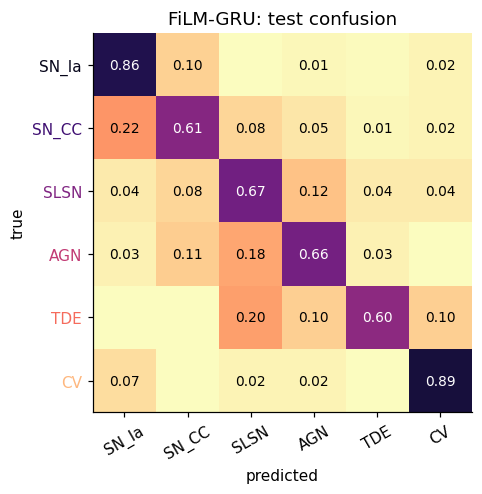

In [8]:
# confusion matrix (row-normalised)
y = test_T[3].numpy(); pred = proba_net.argmax(1)
cm = np.array([[np.mean(pred[y == t] == p) if (y == t).sum() else 0
                for p in range(6)] for t in range(6)])
fig, ax = plt.subplots(figsize=(5.4, 4.6))
ax.imshow(cm, cmap="magma_r", vmin=0, vmax=1)
for t in range(6):
    for p in range(6):
        if cm[t, p] >= 0.01:
            ax.text(p, t, f"{cm[t, p]:.2f}", ha="center", va="center",
                    color="white" if cm[t, p] > 0.5 else "black", fontsize=9)
ax.set_xticks(range(6)); ax.set_xticklabels(SIX, rotation=30)
ax.set_yticks(range(6)); ax.set_yticklabels(SIX)
for lab in ax.get_yticklabels():
    lab.set_color(CLASS_COLOR[lab.get_text()])
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
ax.set_title("FiLM-GRU: test confusion")
plt.tight_layout(); plt.show()

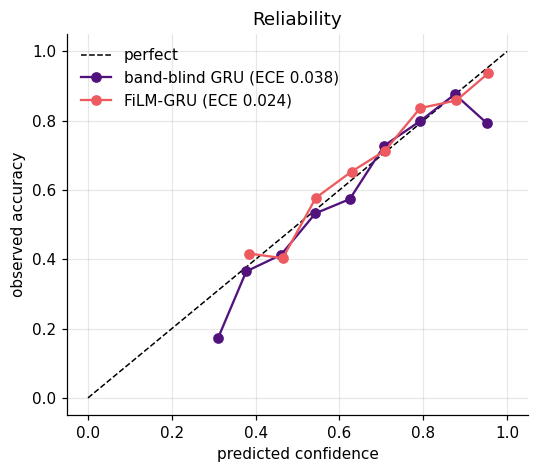

In [9]:
# reliability: does 90% confident mean 90% right?
def reliability(y, p, n_bins=12):
    conf, pred = p.max(1), p.argmax(1)
    correct = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    xs, ys = [], []
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() > 8:
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return np.array(xs), np.array(ys), ece

fig, ax = plt.subplots(figsize=(5, 4.4))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
for p, name, colr in [(proba_blind, "band-blind GRU", plt.cm.magma(0.25)),
                      (proba_net, "FiLM-GRU", plt.cm.magma(0.65))]:
    xs, ys, ece = reliability(y, p)
    ax.plot(xs, ys, "o-", color=colr, label=f"{name} (ECE {ece:.3f})")
ax.set_xlabel("predicted confidence"); ax.set_ylabel("observed accuracy")
ax.legend(frameon=False); ax.set_title("Reliability")
plt.tight_layout(); plt.show()

A point below the diagonal means the classifier is more confident than it is right. Both networks
sit close to the diagonal on this split (ECE 0.038 for the band-blind GRU, 0.024 for the FiLM-GRU),
but the diagram only checks the confidence of the top class, and two thirds of the test objects
are SN Ia. The low precision of the rare classes in the report above is the part of the picture
it does not show. Keep this in mind in the FLARE notebook, where calibration is a design goal.

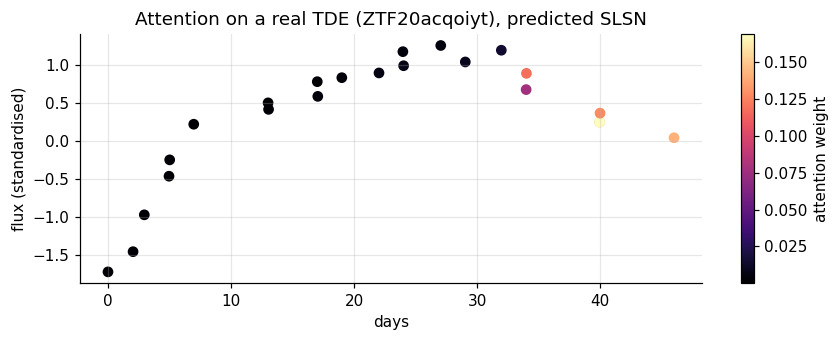

In [10]:
# where did the network look? (attention weights on a real TDE)
tde_ix = np.where(y == SIX.index("TDE"))[0]
i = int(tde_ix[0])
n = int((~test_T[2][i]).sum())
t_days = np.expm1(test_T[0][i, :n, 0].numpy())
w = attn[i, :n].numpy()
fig, ax = plt.subplots(figsize=(8, 3.2))
sc = ax.scatter(t_days, test_T[0][i, :n, 2].numpy(), c=w, cmap="magma", s=36)
plt.colorbar(sc, label="attention weight")
ax.set_xlabel("days"); ax.set_ylabel("flux (standardised)")
ax.set_title(f"Attention on a real TDE ({tables['test'].obj_id[i]}), "
             f"predicted {SIX[pred[i]]}")
plt.tight_layout(); plt.show()

## 7. What we built, and where to take it

We wrote a complete deep classifier for irregular multi-band time series: learned time handling
(P1), band conditioning (P2), attention pooling (P3), class-weighted training with early stopping
on the validation split, and a full evaluation report. The production-scale version of this idea
is bigger and trains longer, but it contains no concept we have not now implemented ourselves.

### Exercises

1. Replace attention pooling with a masked mean
   (`z = (h * (~pad).unsqueeze(-1)).sum(1) / lengths`). What was the learned "where to look"
   worth, and on which metrics?
2. Set `CAP = 30`, an early-warning classifier that sees only the first 30 or so observations.
   Which classes survive? Does the answer make physical sense?
3. Feed the band as three extra input columns instead of FiLM (`embed = nn.Linear(7, d)`,
   `use_film=False`). Concatenation and conditioning carry the same information with different
   wiring: does it matter?
4. Train on the full train split (drop the 700-per-class cap) for more epochs. Which classes gain,
   and how does the gap to the feature-based FLARE classifier change?

### Hackathon

This notebook is the starting point of the **Hyrax integration** track: wrap `LightCurveGRU` as a
Hyrax model, following the patterns from the Hyrax session. A trained torch model with a clean
`forward` is exactly what Hyrax wants to consume.